In [3]:
!pip install seaborn pandas matplotlib

In [1]:
pip install --upgrade jedi

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the data
mpg = pd.read_csv("Lab_assignment_8.csv")  # Update path as needed

# Display first few rows to verify
print("Dataset loaded successfully!")
print(f"Shape: {mpg.shape}")

Dataset loaded successfully!
Shape: (398, 9)


Q1. Inspect the dataset 

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the data
mpg = pd.read_csv("Lab_assignment_8.csv")

# a) First 5 rows
print("a) First 5 rows:")
print(mpg.head())

# b) Shape of the DataFrame
print("\nb) Shape of the DataFrame:")
print(mpg.shape)

# c) Column names
print("\nc) Column names:")
print(mpg.columns.tolist())

# d) Info output
print("\nd) Info output:")
print(mpg.info())

a) First 5 rows:
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  

b) Shape of the DataFrame:
(398, 9)

c) Column names:
['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'name']

d) Info output:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 

Q2. Select columns and filter rows

In [6]:
# Create new DataFrame with selected columns
selected_cols = ['name', 'origin', 'mpg', 'horsepower']
filtered_df = mpg[selected_cols]

# Filter for Japan origin and mpg > 30
japan_high_mpg = filtered_df[(filtered_df['origin'] == 'japan') & (filtered_df['mpg'] > 30)]

# Display first 10 matching rows
print("First 10 matching rows (Japan origin, mpg > 30):")
print(japan_high_mpg.head(10))

First 10 matching rows (Japan origin, mpg > 30):
                    name origin   mpg  horsepower
53   toyota corolla 1200  japan  31.0        65.0
54           datsun 1200  japan  35.0        69.0
129          datsun b210  japan  31.0        67.0
131  toyota corolla 1200  japan  32.0        65.0
144        toyota corona  japan  31.0        52.0
145           datsun 710  japan  32.0        61.0
181     honda civic cvcc  japan  33.0        53.0
198          honda civic  japan  33.0        53.0
204         datsun b-210  japan  32.0        70.0
216    honda accord cvcc  japan  31.5        68.0


Q3. Sort the data and find extreme values

In [7]:
# Part A: Sort by mpg descending, show top 10
print("Part A: Top 10 cars by highest mpg:")
top_mpg = mpg[['name', 'origin', 'mpg']].sort_values('mpg', ascending=False).head(10)
print(top_mpg)

print("\n" + "="*50 + "\n")

# Part B: Sort by weight ascending, show first 3
print("Part B: 3 lightest cars:")
lightest = mpg[['name', 'weight', 'mpg']].sort_values('weight', ascending=True).head(3)
print(lightest)

Part A: Top 10 cars by highest mpg:
                                name  origin   mpg
322                        mazda glc   japan  46.6
329              honda civic 1500 gl   japan  44.6
325             vw rabbit c (diesel)  europe  44.3
394                        vw pickup  europe  44.0
326               vw dasher (diesel)  europe  43.4
244  volkswagen rabbit custom diesel  europe  43.1
309                        vw rabbit  europe  41.5
330             renault lecar deluxe  europe  40.9
324                       datsun 210   japan  40.8
247                   datsun b210 gx   japan  39.4


Part B: 3 lightest cars:
               name  weight   mpg
54      datsun 1200    1613  35.0
144   toyota corona    1649  31.0
343  toyota starlet    1755  39.1


Q4. Create a new column and summarise with groupby 

In [8]:
# Add efficiency_level column
def get_efficiency_level(mpg_val):
    if mpg_val < 20:
        return 'Low'
    elif 20 <= mpg_val < 30:
        return 'Medium'
    else:  # mpg >= 30
        return 'High'

mpg['efficiency_level'] = mpg['mpg'].apply(get_efficiency_level)

# Display first 10 rows of name, mpg, efficiency_level
print("First 10 rows with efficiency_level:")
print(mpg[['name', 'mpg', 'efficiency_level']].head(10))

print("\n" + "="*50 + "\n")

# Mean mpg by origin (rounded to 2 decimals)
print("Mean mpg by origin:")
mean_mpg_origin = round(mpg.groupby('origin')['mpg'].mean(), 2)
print(mean_mpg_origin)

print("\n" + "="*50 + "\n")

# Mean horsepower by efficiency_level (rounded to 2 decimals)
print("Mean horsepower by efficiency level:")
mean_hp_level = round(mpg.groupby('efficiency_level')['horsepower'].mean(), 2)
print(mean_hp_level)

First 10 rows with efficiency_level:
                        name   mpg efficiency_level
0  chevrolet chevelle malibu  18.0              Low
1          buick skylark 320  15.0              Low
2         plymouth satellite  18.0              Low
3              amc rebel sst  16.0              Low
4                ford torino  17.0              Low
5           ford galaxie 500  15.0              Low
6           chevrolet impala  14.0              Low
7          plymouth fury iii  14.0              Low
8           pontiac catalina  14.0              Low
9         amc ambassador dpl  15.0              Low


Mean mpg by origin:
origin
europe    27.89
japan     30.45
usa       20.08
Name: mpg, dtype: float64


Mean horsepower by efficiency level:
efficiency_level
High       70.72
Low       139.70
Medium     89.36
Name: horsepower, dtype: float64


Q5. Use seaborn to create a count plot and a bar plot


Q5: Creating plots...


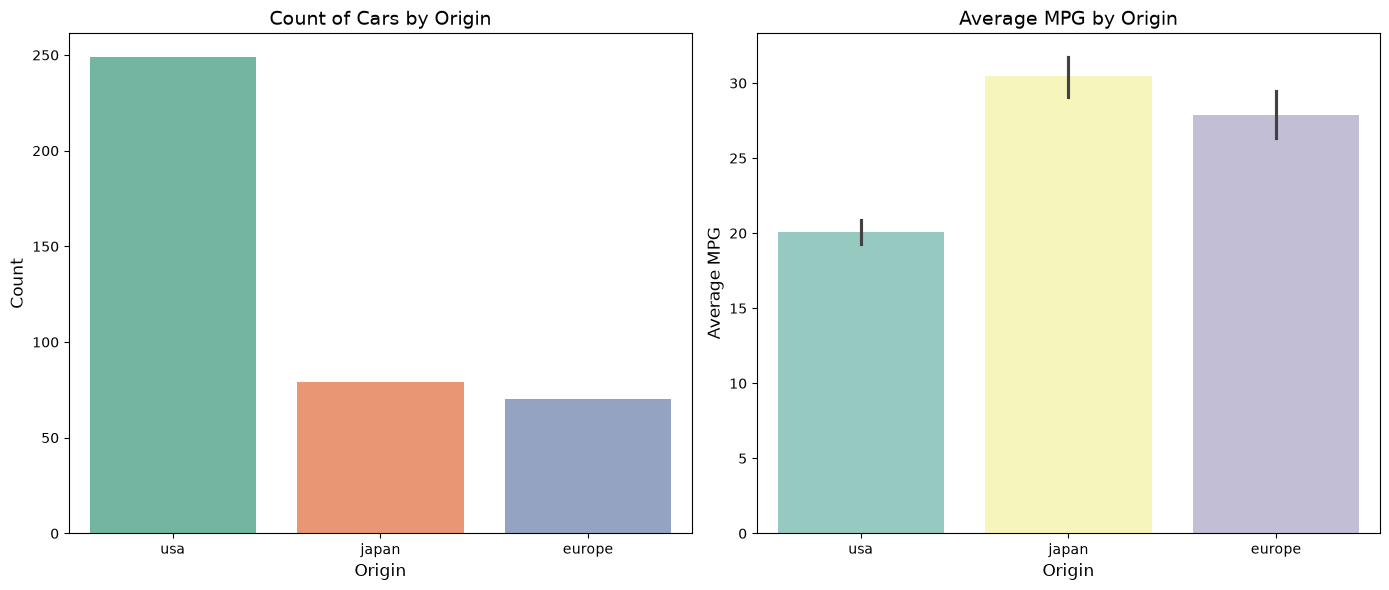

In [12]:
# Q5: Count plot and bar plot - Updated to avoid FutureWarning
print("\n" + "="*60)
print("Q5: Creating plots...")
print("="*60)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Part A: Count plot - using hue
sns.countplot(data=mpg, x='origin', hue='origin', ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Count of Cars by Origin', fontsize=14)
axes[0].set_xlabel('Origin', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)

# Part B: Bar plot - using hue
sns.barplot(data=mpg, x='origin', y='mpg', hue='origin', ax=axes[1], palette='Set3', legend=False)
axes[1].set_title('Average MPG by Origin', fontsize=14)
axes[1].set_xlabel('Origin', fontsize=12)
axes[1].set_ylabel('Average MPG', fontsize=12)

plt.tight_layout()
plt.show()

Q6. Use seaborn to create a pair plot

Original shape: (398, 10)
Clean shape: (392, 4)
Rows removed: 6


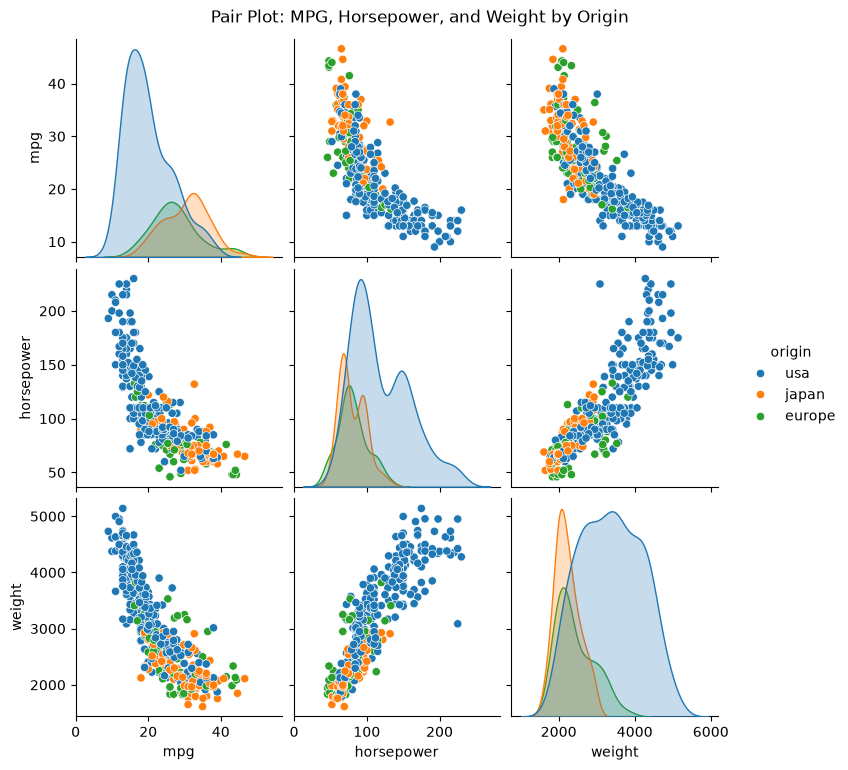

In [10]:
# Remove rows with missing values in specified columns
cols_needed = ['mpg', 'horsepower', 'weight', 'origin']
clean_data = mpg[cols_needed].dropna()

print(f"Original shape: {mpg.shape}")
print(f"Clean shape: {clean_data.shape}")
print(f"Rows removed: {mpg.shape[0] - clean_data.shape[0]}")

# Create pair plot
sns.pairplot(clean_data, vars=['mpg', 'horsepower', 'weight'], hue='origin', diag_kind='kde')
plt.suptitle('Pair Plot: MPG, Horsepower, and Weight by Origin', y=1.02)
plt.show()